# Proximity Operations
The **Hill-Clohessy-Wiltshire** (HCW) equations are a fundamental tool in astrodynamics for analyzing and controlling the relative motion between two spacecrafts, a crucial aspect of formation flying, rendezvous, and docking (also called **RPO**, Redezvous and Proximity Operations). They are a set of linearized differential equations that describe the motion of a *chaser* spacecraft relative to a *target* spacecraft, under several key assumptions.

## The Underlying Concept
The motion of a single satellite around a central body (like Earth) is governed by the nonlinear equations of orbital mechanics. When you have two satellites flying in close proximity, their motion is also coupled. The HCW equations simplify this complex, nonlinear problem by making some simplifying assumptions.

The core idea is to describe the relative motion in a Radial, In-track, Cross-track (**RIC**) reference frame, which is a rotating coordinate system centered on the target spacecraft:


<center><img src="Images/RIC.png" alt="Drawing" style="width: 600px;"/><center>


- **X-axis**: Points radially outward from the central body (along the local vertical)
- **Y-axis**: Points in the direction of the velocity (along the local horizontal)
- **Z-axis**: Points out of the orbital plane, completing a right-handed coordinate system

Under those assumptions, the target's orbit plane is the **XY** plane
The chaser's position relative to the target is then described by the coordinates (x,y,z) in this rotating frame.

## Key Assumptions for HCW Equations

The HCW equations are valid under the following conditions:

- **Circular Target Orbit**: the target spacecraft's orbit is assumed to be perfectly circular
- **Small Separation**: the distance between the chief and the deputy is assumed to be very small compared to the orbital radius of the chief. This allows for a linearization of the gravitational forces
- **Two-Body Problem**: only the gravitational force of the central body is considered. Perturbations like atmospheric drag, solar radiation pressure, and the gravitational effects of other celestial bodies are ignored

These assumptions make the equations simple enough to have a closed-form, analytical solution, providing a powerful and intuitive tool for mission design.

## The HCW Equations

The HCW equations for the chaser's motion relative to the target are:

$$ \boxed{\begin{matrix}
\ddot{x} -2n\dot{y}-3n^{2}x=0\\
 \ddot{y}+2n\dot{x}=0\\
\ddot{z}+n^{2}z=0
\end{matrix} }$$
Where:

- $x$, $y$, and $z$ are the relative position components of the deputy with respect to the chief in the LVLH frame
- $\dot{x}$, $\dot{y}$ and $\dot{z}$ are the relative velocity components
- $\ddot{x}$, $\ddot{y}$ and $\ddot{z}$ are the relative accelerations
- $n$ is the mean motion, which is equal to $ \sqrt{\dfrac{\mu }{a^{3}}}$

The equations are a bit unusual: the $x$ and $y$ motions are coupled, meaning the motion in the radial direction affects the motion in the along-track direction and vice-versa: this is due to the Coriolis and gravity gradient forces. The $z$ motion is decoupled from the in-plane motion and is a simple harmonic oscillator. This means the out-of-plane motion is a simple oscillation with a period equal to the chief's orbital period.

## Chaser's Path Relative to Target

Depending on the state difference (position, velocity) of the chaser respect to the target, its relative path could be either a closed (bounded) path or the sum of a periodic and a secular variation with linearly growing terms.

The resulting relative path between the target and the chaser depends on the initial state of the chaser respect to the target: 

$$ \left\{ \begin{matrix}
x_0 & y_0 & z_0 & \dot{x}_0 & \dot{y}_0 & \dot{z}_0 \\
\end{matrix}\right\} $$

The general solution to these equations reveals both periodic and secular, linearly growing terms. Here the effects of individual changes in the initial state vector's components:

<b>1) Changes in radial position ($x_0$): unbounded motion</b>

The chaser drifts half loops in the in-track direction; if negative, this causes a drift in the positive in-track direction

<b>2) Changes in in-track position ($y_0$): bounded motion</b>

The chaser stays at constant distance to the target

<b>3) Changes in cross-track position ($z_0$): bounded motion</b>

The chaser oscillates along the $y$ axes

<b>4) Changes in radial rate ($\dot{x}_0$): bounded motion</b>

The chaser is on a closed ellipse around the target. The direction of motion is counterclockwise as seen from the $x-y$ plane. Any change in the initial in-track position will translate the position of the ellipse along the $y$ axis

<b>5) Changes in in-track rate ($\dot{y}_0$): unbounded motion</b>

The chaser drifts full loops in the in-track direction; if negative, this causes a drift in the positive in-track direction

<b>6) Changes in cross-track rate ($\dot{y}_0$): unbounded motion</b>

The chaser oscillates along the $y$ axes with a slow drift towards the negative in-track direction


Note that, given an initial radial position $x_0$, there is a specific value of the in-track rate $\dot{y}_0$ which, in the HCW approximation, leads to a closed (elliptical) pattern:

$$\boxed{\dot{y}_0 = -2 n x_0}$$



## Amplitudes of Oscillations

### In-Plane Amplitude

The radial ($x$) and along-track ($y$) motions are coupled. For a bounded (closed) orbit the radial motion oscillates with an amplitude $A_{x}$:

$$A_{x}=\sqrt{\left ( 3x_0+\frac{2\dot{y}_0}{n} \right )^{2}+\left ( \frac{\dot{x}_0}{n} \right )^{2}}$$

In the HCW model the in-plane relative motion follows a $2\times 1$ ellipse. The amplitude in the in-track ($y$) direction is exactly twice the amplitude in the radial ($x$) direction ($A_{y}=2A_{x}$):

<center><img src="Images/HCW_bounded.png" alt="Drawing" style="width: 800px;"/><center>

    





### Out-of-Plane Amplitude

The cross-track motion ($z$) is a decoupled simple harmonic oscillator with a period equal to the orbit's period. Its amplitude is given by:

$$A_{z}=\sqrt{z_0^{2}+\left ( \frac{\dot{z}_0}{n} \right )^{2}}$$


## Try it Out!

Select an (or define a new) initial state from the list below and run the code snippet to see the relative path between the target and the chaser

Mean motion = 0.0011553163126390323 rad/sec
Radial oscillation amplitude = 50 m
Intrack oscillation amplitude = 100 m
Critical intrack rate for drift stopping = -0.11553163126390323 m/s
Critical intrack rate for straight line = -0.08664872344792741 m/s


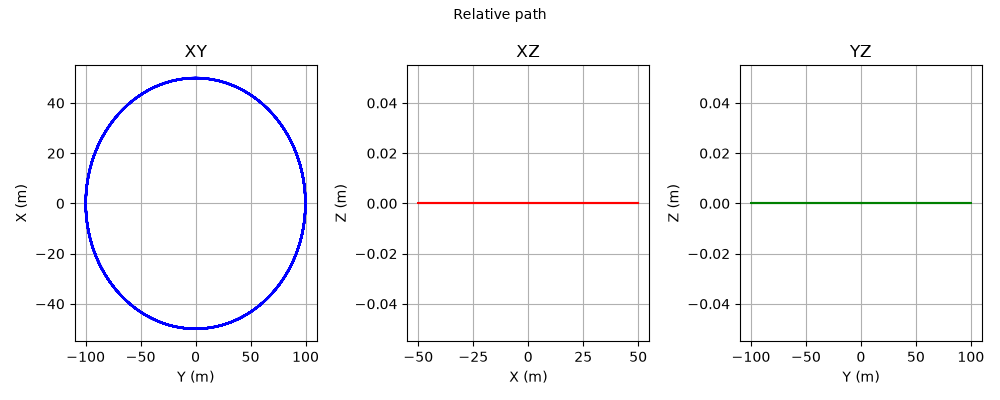

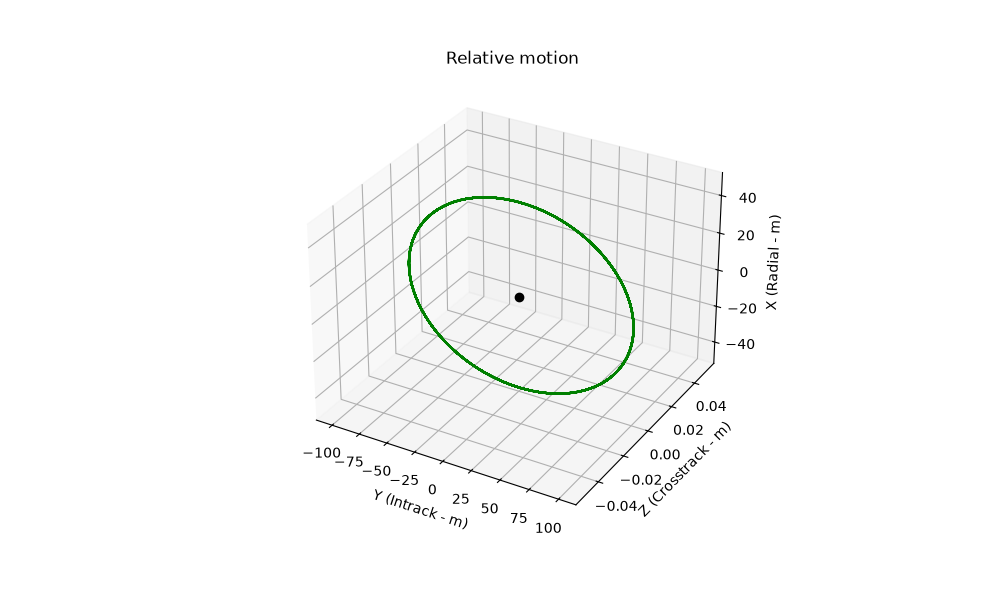

In [3]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from routines import *
%matplotlib widget

###### set the simulation conditions #########
alt = 306  # km - altitude of the target object

#initialState = [-50, 0, 0, 0, 0, 0] #Case 1) radial position change only
#initialState = [50, 0, 0, 0, -0.118, 0] #Case 2) radial position and intrack rate change
#initialState = [0, 0, 0, 0.02, 0, 0] #Case 3) radial rate change only
#initialState = [0, 60, 0, 0.05, 0, 0] #Case 4) radial rate and intrack position change

initialState = [50, 0, 0, 0, -0.11553163126390323, 0]

numRevs = 20 # number of revolutions to cover
############################################

 
plot_hcw(initialState, alt, numRevs)